In [ ]:
!pip install qutip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 60.0 MB/s eta 0:00:00


In [ ]:
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt

The objective of this notebook is to introduce the Monte Carlo wave-function method implemented in QuTiP and verify numerically that the ensemble average of quantum trajectories reproduces the solution of the Lindblad master equation.

# Open Quantum Systems: Quantum jump trajectories and stochastic evolution

So far, the system has been treated as an ideal closed quantum system, where the dynamics consists of a sequence of unitary displacement operations followed by projective parity measurements. However, the system continuously interacts with its environment and must therefore be described as an **open quantum system**.

The evolution of an open quantum system is governed by the **Lindblad master equation**

$$
\boxed{
\frac{d\rho}{dt}
=
-i[H,\rho]
+
\sum_k
\mathcal{D}[L_k]\rho,
}
$$

where

$$
\mathcal{D}[L]\rho
=
L\rho L^\dagger
-
\frac12
\left(
L^\dagger L\rho
+
\rho L^\dagger L
\right)
$$

is the Lindblad dissipator, \(H\) is the system Hamiltonian, and $L_k$ are the collapse (jump) operators describing the interaction with the environment.

Unlike the Schrödinger equation, which preserves pure states, the Lindblad equation evolves the density matrix and naturally accounts for decoherence, dissipation and continuous measurements.



Although the Lindblad equation is deterministic, it can be interpreted as the statistical average of many stochastic realizations of the system dynamics. This description is known as the **quantum-jump unraveling**. Instead of evolving the density matrix directly, one considers individual quantum trajectories described by a pure state

$$
|\psi_c(t)\rangle,
$$

where the subscript \(c\) denotes that the evolution is **conditioned** on a particular measurement record.

Each trajectory evolves through two different processes:

- **Continuous evolution** between jumps.
- **Instantaneous quantum jumps** occurring randomly.

Between jumps, the evolution is governed by the **non-Hermitian effective Hamiltonian**, so the norm of the wavefunction decreases continuously. This loss of norm represents the probability that a quantum jump has not yet occurred.

$$
\boxed{
H_{\mathrm{eff}}
=
H
-
\frac{i}{2}
\sum_k
L_k^\dagger L_k.
}
$$



During an infinitesimal time interval \(dt\), the probability that a jump occurs through channel \(k\) is

$$
\boxed{
p_k
=
dt\,
\langle
L_k^\dagger L_k
\rangle.
}
$$

If no jump occurs, the state evolves smoothly under the effective Hamiltonian.

If a jump is detected, the state is instantaneously projected according to

$$
\boxed{
|\psi\rangle
\longrightarrow
\frac{L_k|\psi\rangle}
{\sqrt{\langle L_k^\dagger L_k\rangle}}.
}
$$

The complete stochastic evolution is therefore described by the stochastic Schrödinger equation

$$
d|\psi_c\rangle
=
-iH_{\mathrm{eff}}|\psi_c\rangle\,dt
+
\sum_k
\left(
\frac{L_k}
{\sqrt{\langle L_k^\dagger L_k\rangle}}
-
I
\right)
|\psi_c\rangle\,dN_k,
$$

where \(dN_k\) is a Poisson stochastic increment satisfying

$$
dN_k\in\{0,1\},
$$

with

$$
E[dN_k]
=
dt\,
\langle
L_k^\dagger L_k
\rangle.
$$

Thus, each realization follows a different random sequence of jumps and consequently generates a different quantum trajectory.

## Monte Carlo wave-function method

The stochastic evolution is efficiently simulated using the **Monte Carlo wave-function (MCWF)** method, implemented in QuTiP through the function `mcsolve`.

Each simulation produces one possible realization of the monitored dynamics.

Different runs generate different quantum trajectories because the jump events occur at random times.


## Ensemble average

A single trajectory does not reproduce the Lindblad evolution.

However, averaging over a sufficiently large number of independent trajectories recovers the deterministic solution of the master equation,

$$
\boxed{
\rho(t)
=
\mathbb{E}
\left[
\rho_c(t)
\right],
}
$$

where $\mathbb{E}[\cdot]$ denotes the statistical average over all possible stochastic realizations.

This relation establishes the connection between the stochastic description and the deterministic Lindblad equation.



The goal of this section is to verify this correspondence numerically.

First, multiple quantum trajectories will be generated using `mcsolve`, and the corresponding Wigner functions will be analyzed.

Next, these trajectories will be averaged and compared with the solution obtained directly from the Lindblad master equation using `mesolve`.

Both the Wigner function and relevant observables
will be compared in order to demonstrate that the ensemble average of stochastic trajectories converges to the deterministic Lindblad evolution.

## One Trajectory

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt


N = 140

alpha = 2.0
gamma = 0.5

T = 5.0
n_steps = 300

times = np.linspace(0, T, n_steps)

a = qt.destroy(N)

I = qt.qeye(N)

parity = sum(
    (-1)**n * qt.basis(N, n) * qt.basis(N, n).dag()
    for n in range(N)
)

P_even = (I + parity)/2
P_odd  = (I - parity)/2


# Hamiltonian

H = 1j*(alpha*a.dag() - np.conjugate(alpha)*a)


# Collapse operators

c_ops = [
    np.sqrt(gamma)*P_even,
    np.sqrt(gamma)*P_odd
]


psi0 = qt.basis(N,0)


# Observable

n_op = a.dag()*a

options = {
    "store_states": True,
    "keep_runs_results": True,
}

result = qt.mcsolve(
    H,
    psi0,
    times,
    c_ops,
    e_ops=[n_op],
    ntraj=1,
    options=options
)

100.0%. Run time:   0.00s. Est. time left: 00:00:00:00
Total run time:   0.02s


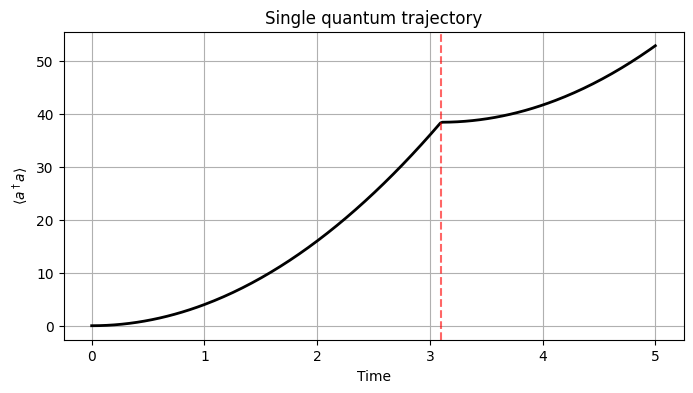

[(np.float64(3.099444078290637),)]
[(0,)]


In [ ]:
plt.figure(figsize=(8,4))

plt.plot(
    times,
    result.runs_expect[0][0],
    lw=2,
    color="black"
)

for t in result.col_times[0]:
    plt.axvline(
        t,
        color="red",
        ls="--",
        alpha=0.6
    )

plt.xlabel("Time")
plt.ylabel(r"$\langle a^\dagger a\rangle$")
plt.title("Single quantum trajectory")

plt.grid(True)

plt.show()

print(result.col_times)
print(result.col_which)

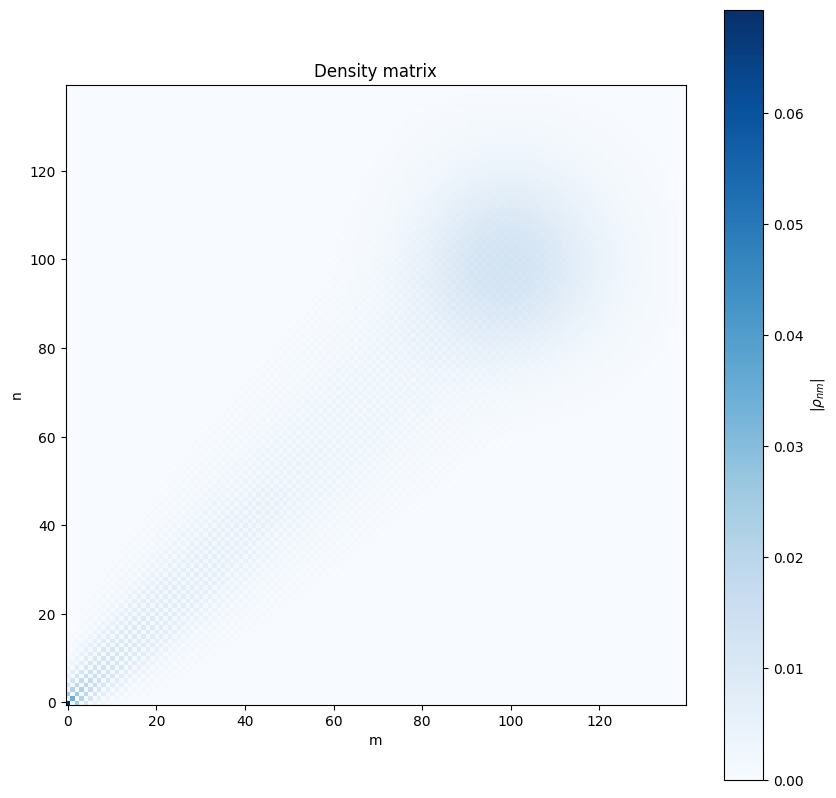

In [ ]:
result_me = qt.mesolve(
    H,
    psi0,
    times,
    c_ops,
    options={"store_states": True}
)

rho = result_me.states[-1]
plt.figure(figsize=(10,10))

plt.imshow(
    np.abs(rho.full()),
    origin="lower",
    cmap="Blues",
     interpolation="none"
)

plt.xlabel("m")
plt.ylabel("n")

plt.colorbar(label=r"$|\rho_{nm}|$")

plt.title("Density matrix")

plt.show()

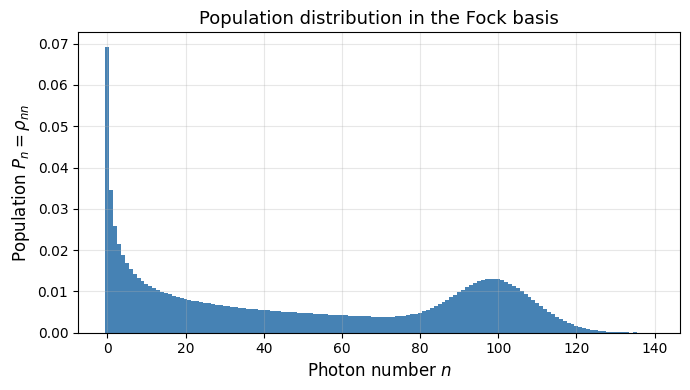

In [ ]:
population = np.real(rho.diag())

plt.figure(figsize=(7,4))

plt.bar(
    np.arange(N),
    population,
    color="steelblue",
    width=1.0
)

plt.xlabel(r"Photon number $n$", fontsize=12)
plt.ylabel(r"Population $P_n=\rho_{nn}$", fontsize=12)

plt.title("Population distribution in the Fock basis", fontsize=13)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

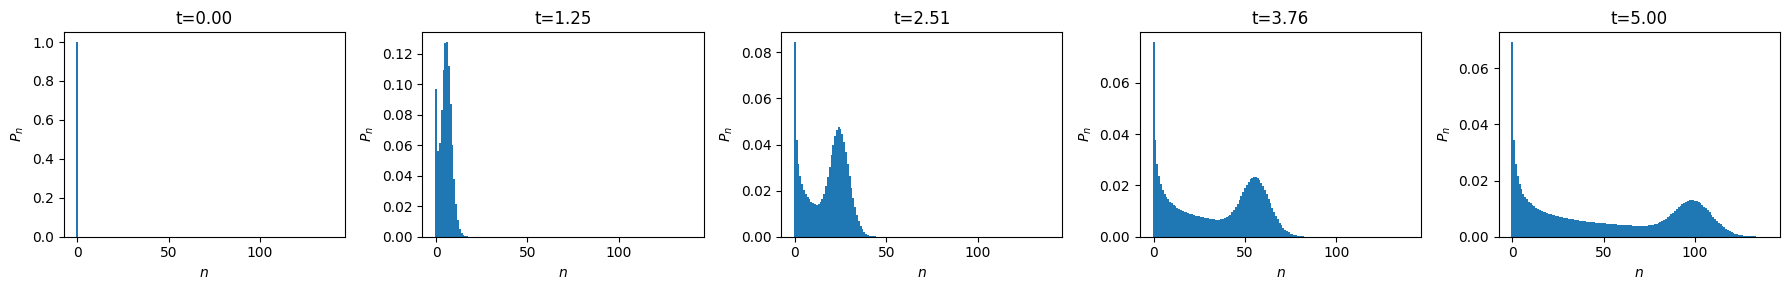

In [ ]:
indices = [0, 75, 150, 225, 299]

fig, axes = plt.subplots(1,5, figsize=(18,3))

for ax, i in zip(axes, indices):

    population = np.real(result_me.states[i].diag())

    ax.bar(np.arange(N), population, width=1)

    ax.set_title(f"t={times[i]:.2f}")
    ax.set_xlabel(r"$n$")
    ax.set_ylabel(r"$P_n$")

plt.tight_layout()
plt.show()

The coherent drive shifts the population towards larger photon numbers, while **the parity measurement induces decoherence**, broadening the distribution and preserving a finite population at low photon numbers without introducing photon loss.

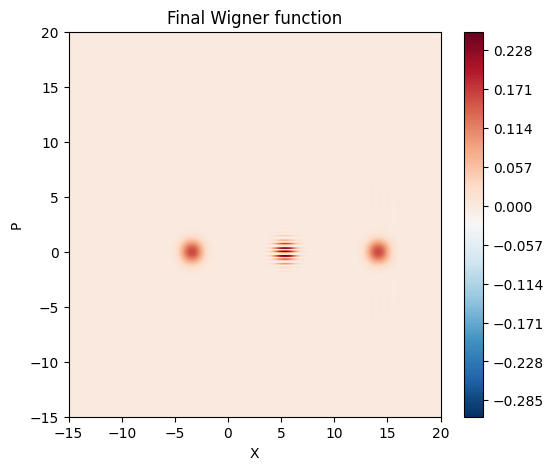

In [ ]:
psi_final = result.trajectories[0].states[-1]

rho_final = qt.ket2dm(psi_final)

x = np.linspace(-15,20,250)

W = qt.wigner(rho_final,x,x)

plt.figure(figsize=(6,5))

plt.contourf(x,x,W,200,cmap="RdBu_r")

plt.xlabel("X")
plt.ylabel("P")

plt.title("Final Wigner function")

plt.colorbar()

plt.show()

### Hilbert-Space Truncation Analysis

The cavity field is described in the Fock basis:
$$\{|0\rangle, |1\rangle, |2\rangle, \ldots\}$$
which is, in principle, an infinite-dimensional Hilbert space. Therefore, all numerical simulations require truncating the Hilbert space to a finite dimension: $N$. The chosen value of $N$ must be sufficiently large so that the neglected Fock states remain essentially unoccupied during the entire time evolution.

A first analytical estimate of the required Hilbert-space dimension can be obtained by considering the ideal case without measurements:
$$\gamma = 0$$
In this limit, the system evolves only under the coherent driving Hamiltonian:
$$H = i(\alpha a^\dagger - \alpha^* a)$$
whose exact solution is a coherent state:
$$| \psi(t) \rangle = D(\alpha t) |0\rangle$$


The photon-number distribution of a coherent state is Poissonian:
$$P_n = e^{-|\alpha t|^2} \frac{|\alpha t|^{2n}}{n!}$$
with mean photon number:
$$\langle n(t) \rangle = |\alpha t|^2$$
and standard deviation:
$$\sigma_n = \sqrt{\langle n(t) \rangle}$$
Consequently, the maximum average photon number expected during the simulation is:
$$\langle n \rangle_{\text{max}} = |\alpha T|^2$$
where:
$$T$$
is the final simulation time.

A convenient estimate for the Hilbert-space dimension is for example:
$$N \gtrsim |\alpha T|^2 + 4\sqrt{|\alpha T|^2}$$
which ensures that the tail of the Poisson distribution is negligible before reaching the truncation boundary.



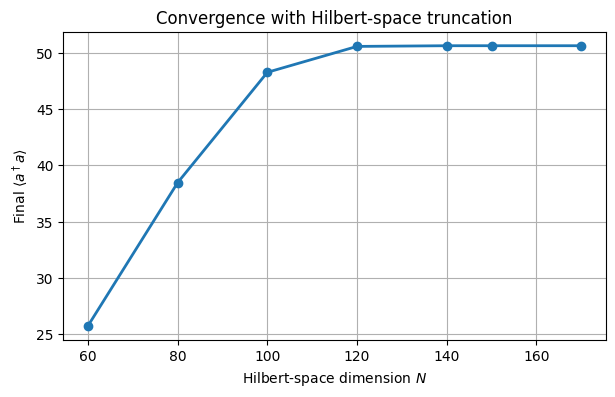

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt


alpha = 2.0
gamma = 0.5

T = 5.0
n_steps = 300
times = np.linspace(0, T, n_steps)

N_values = [60, 80, 100, 120, 140, 150, 170]

final_expectation = []

for N in N_values:

    a = qt.destroy(N)

    I = qt.qeye(N)

    parity = sum(
        (-1)**n * qt.basis(N, n) * qt.basis(N, n).dag()
        for n in range(N)
    )

    P_even = (I + parity)/2
    P_odd  = (I - parity)/2

    H = 1j*(alpha*a.dag() - np.conjugate(alpha)*a)

    c_ops = [
        np.sqrt(gamma)*P_even,
        np.sqrt(gamma)*P_odd
    ]

    psi0 = qt.basis(N,0)

    n_op = a.dag()*a

    result = qt.mesolve(
        H,
        psi0,
        times,
        c_ops,
        e_ops=[n_op]
    )

    final_expectation.append(result.expect[0][-1])

plt.figure(figsize=(7,4))

plt.plot(
    N_values,
    final_expectation,
    "o-",
    lw=2
)

plt.xlabel("Hilbert-space dimension $N$")
plt.ylabel(r"Final $\langle a^\dagger a\rangle$")
plt.title("Convergence with Hilbert-space truncation")

plt.grid(True)

plt.show()

## Discussion of the Parameters

The dynamics of a quantum trajectory is determined by the competition between the coherent evolution generated by the Hamiltonian and the stochastic interaction with the environment. These two processes are controlled by the parameters $\alpha$ and $\gamma$ respectively.

The coherent evolution is generated by the Hamiltonian

$$
H=i\left(\alpha a^\dagger-\alpha^*a\right),
$$

which is the generator of the displacement operator

$$
D(\alpha)=\exp\left(\alpha a^\dagger-\alpha^*a\right).
$$

Therefore, the parameter $\alpha$ controls the strength of the coherent displacement in phase space. Increasing the magnitude of $|\alpha|$ produces a faster displacement of the quantum state, resulting in a more rapid variation of the field amplitude and a larger increase in the mean photon number. Conversely, for smaller values of $|\alpha|$, the coherent evolution becomes slower and the state remains closer to its initial configuration.

The interaction with the environment is described through the collapse operators

$$
L_0=\sqrt{\gamma}\,P_{\mathrm{even}},
$$

and

$$
L_1=\sqrt{\gamma}\,P_{\mathrm{odd}}.
$$

The probability that a quantum jump occurs during an infinitesimal time interval $dt$ is

$$
p_k=dt\,\langle L_k^\dagger L_k\rangle.
$$

Since

$$
L_k^\dagger L_k=\gamma P_k,
$$

the jump probability is directly proportional to $\gamma$. Consequently, increasing $\gamma$ leads to more frequent quantum jumps, while decreasing $\gamma$ reduces the jump rate and the dynamics approaches the coherent unitary evolution generated by the Hamiltonian.

The qualitative behavior of the system is therefore determined by the competition between these two parameters. Different choices of these parameters give rise to different dynamical regimes, ranging from nearly unitary evolution to dynamics dominated by frequent stochastic projections.

To characterize the evolution of a single quantum trajectory, the expectation value of the photon number operator

$$
\langle a^\dagger a\rangle
$$

is monitored as a function of time.

This observable measures the average number of photons stored in the bosonic mode and therefore provides a direct indication of the system's energy. It is particularly suitable for analyzing quantum trajectories because it clearly reveals the competition between coherent driving and stochastic quantum jumps.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

# Hilbert space
N = 140
T = 5.0
n_steps = 300
times = np.linspace(0, T, n_steps)

a = qt.destroy(N)
I = qt.qeye(N)

parity = sum(
    (-1)**n * qt.basis(N, n) * qt.basis(N, n).dag()
    for n in range(N)
)

P_even = (I + parity)/2
P_odd  = (I - parity)/2

psi0 = qt.basis(N,0)

n_op = a.dag()*a

options = {
    "store_states": True,
    "keep_runs_results": True,
}

def run_trajectory(alpha, gamma):

    H = 1j*(alpha*a.dag() - np.conjugate(alpha)*a)

    c_ops = [
        np.sqrt(gamma)*P_even,
        np.sqrt(gamma)*P_odd
    ]

    result = qt.mcsolve(
    H,
    psi0,
    times,
    c_ops,
    e_ops=[n_op],
    ntraj=1,
    options=options,
    seeds=1234
)
    return result

100.0%. Run time:   0.00s. Est. time left: 00:00:00:00
Total run time:   0.02s
100.0%. Run time:   0.00s. Est. time left: 00:00:00:00
Total run time:   0.02s
100.0%. Run time:   0.00s. Est. time left: 00:00:00:00
Total run time:   0.02s


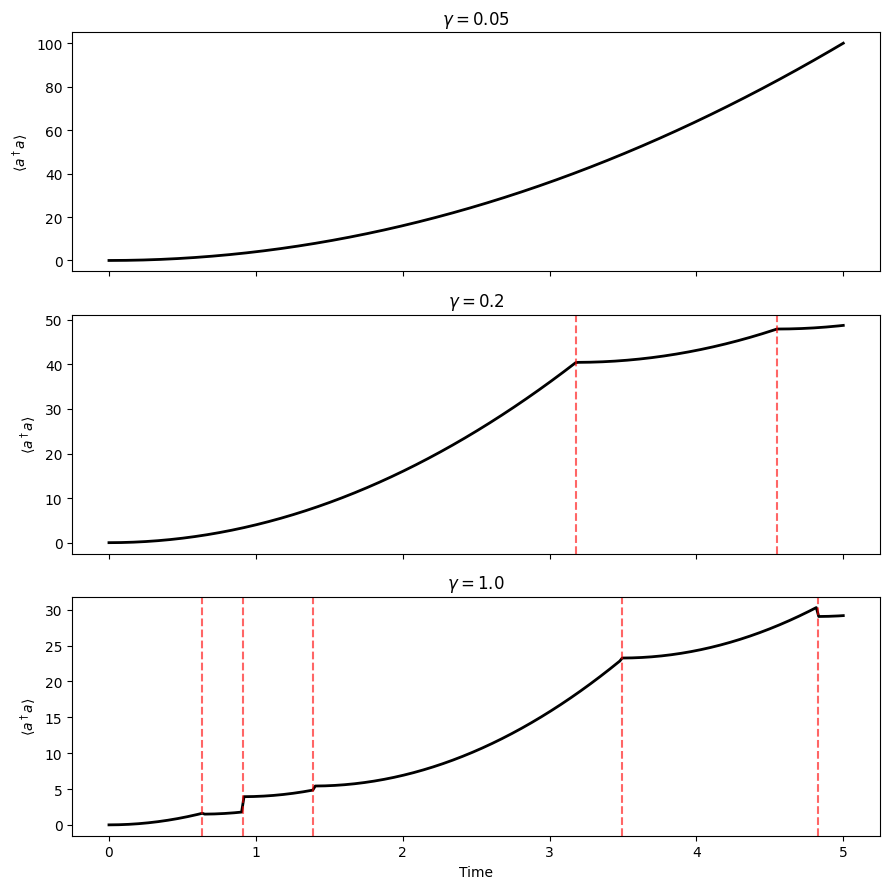

In [ ]:
alpha = 2.0

gammas = [0.05, 0.2, 1.0]

fig, axes = plt.subplots(3,1, figsize=(9,9), sharex=True)

for ax, gamma in zip(axes, gammas):

    result = run_trajectory(alpha, gamma)

    ax.plot(
        times,
        result.runs_expect[0][0],
        color="black",
        lw=2
    )

    for t in result.col_times[0]:
        ax.axvline(
            t,
            color="red",
            ls="--",
            alpha=0.6
        )

    ax.set_ylabel(r"$\langle a^\dagger a\rangle$")
    ax.set_title(rf"$\gamma={gamma}$")

axes[-1].set_xlabel("Time")

plt.tight_layout()
plt.show()

100.0%. Run time:   0.00s. Est. time left: 00:00:00:00
Total run time:   0.01s
100.0%. Run time:   0.00s. Est. time left: 00:00:00:00
Total run time:   0.01s
100.0%. Run time:   0.00s. Est. time left: 00:00:00:00
Total run time:   0.01s


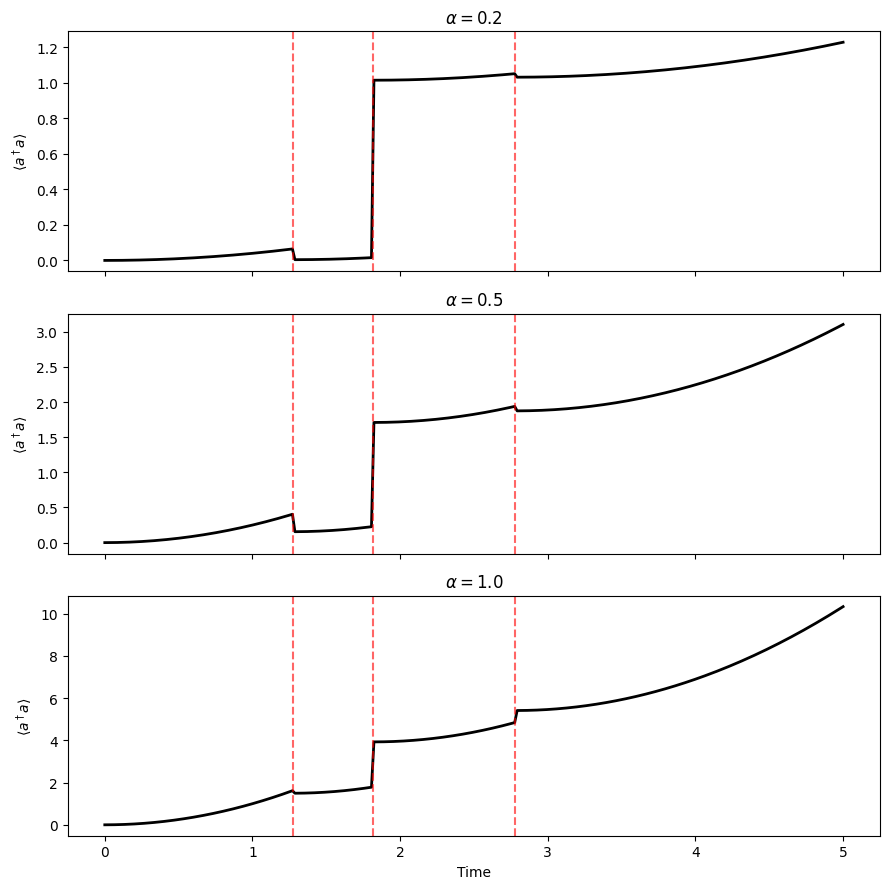

In [ ]:
gamma = 0.5

alphas = [0.2, 0.5, 1.0]

fig, axes = plt.subplots(3,1, figsize=(9,9), sharex=True)

for ax, alpha in zip(axes, alphas):

    result = run_trajectory(alpha, gamma)

    ax.plot(
        times,
        result.runs_expect[0][0],
        color="black",
        lw=2
    )

    for t in result.col_times[0]:
        ax.axvline(
            t,
            color="red",
            ls="--",
            alpha=0.6
        )

    ax.set_ylabel(r"$\langle a^\dagger a\rangle$")
    ax.set_title(rf"$\alpha={alpha}$")

axes[-1].set_xlabel("Time")

plt.tight_layout()
plt.show()

### Ensemble Average of Quantum Trajectories


The stochastic evolution described by the Monte Carlo wave-function method corresponds to a **single realization** of the measurement process.
Since the occurrence of quantum jumps is inherently probabilistic, two independent simulations starting from the same initial state generally produce different trajectories. Therefore, a single trajectory cannot reproduce the deterministic dynamics predicted by the Lindblad master equation.

The connection between the stochastic and deterministic descriptions is established through the ensemble average of many independent trajectories. If the density matrix associated with the $i$-th trajectory is denoted by

$$
\rho_c^{(i)}(t)=|\psi_c^{(i)}(t)\rangle\langle\psi_c^{(i)}(t)|,
$$

the density matrix of the open quantum system is obtained as

$$
\rho(t)
=
\mathbb{E}
\left[
\rho_c(t)
\right]
=
\lim_{N_{\rm traj}\rightarrow\infty}
\frac{1}{N_{\rm traj}}
\sum_{i=1}^{N_{\rm traj}}
\rho_c^{(i)}(t),
$$

where $N_{\rm traj}$ is the number of independent quantum trajectories.

Consequently, the expectation value of any observable $A$ satisfies

$$
\langle A\rangle
=
{\rm Tr}\!\left[\rho(t)A\right]
=
\mathbb{E}
\left[
\langle\psi_c|A|\psi_c\rangle
\right].
$$

In particular, for the photon number operator,

$$
n=a^\dagger a,
$$

the ensemble average becomes

$$
\langle n(t)\rangle
=
\frac{1}{N_{\rm traj}}
\sum_{i=1}^{N_{\rm traj}}
\langle\psi_c^{(i)}(t)|
a^\dagger a
|\psi_c^{(i)}(t)\rangle.
$$

As the number of trajectories increases, statistical fluctuations become progressively smaller and the Monte Carlo average converges to the deterministic solution of the Lindblad master equation.

To verify this correspondence numerically, the expectation value of the photon number is computed using two independent approaches:

- the Monte Carlo wave-function method (`mcsolve`), where the observable is averaged over a large number of stochastic trajectories;

- the Lindblad master equation (`mesolve`), which directly evolves the density matrix.

Agreement between these two approaches demonstrates that the stochastic quantum trajectories constitute an unraveling of the Lindblad equation and that their ensemble average reproduces the deterministic dynamics of the open quantum system.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

# Hilbert space
N = 140
T = 5.0
n_steps = 300
ntraj = 500
times = np.linspace(0, T, n_steps)

a = qt.destroy(N)
I = qt.qeye(N)

parity = sum(
    (-1)**n * qt.basis(N, n) * qt.basis(N, n).dag()
    for n in range(N)
)

P_even = (I + parity)/2
P_odd  = (I - parity)/2

psi0 = qt.basis(N,0)

n_op = a.dag()*a

options = {
    "store_states": True,
    "keep_runs_results": True,
}

def run_simulation(alpha, gamma):

    H = 1j*(alpha*a.dag() - np.conjugate(alpha)*a)

    c_ops = [
        np.sqrt(gamma)*P_even,
        np.sqrt(gamma)*P_odd
    ]

    result_mc = qt.mcsolve(
    H,
    psi0,
    times,
    c_ops,
    e_ops=[n_op],
    ntraj=ntraj
)
    result_me = qt.mesolve(
    H,
    psi0,
    times,
    c_ops,
    e_ops=[n_op]
)
    return result_mc, result_me

In [ ]:
alpha = 2.0
gamma = 0.5

result_mc, result_me = run_simulation(alpha, gamma)

10.0%. Run time:   0.36s. Est. time left: 00:00:00:03
20.0%. Run time:   0.76s. Est. time left: 00:00:00:03
30.0%. Run time:   1.17s. Est. time left: 00:00:00:02
40.0%. Run time:   1.59s. Est. time left: 00:00:00:02
50.0%. Run time:   1.96s. Est. time left: 00:00:00:01
60.0%. Run time:   2.33s. Est. time left: 00:00:00:01
70.0%. Run time:   2.73s. Est. time left: 00:00:00:01
80.0%. Run time:   3.10s. Est. time left: 00:00:00:00
90.0%. Run time:   3.47s. Est. time left: 00:00:00:00
100.0%. Run time:   3.86s. Est. time left: 00:00:00:00
Total run time:   3.87s


In [ ]:
mc_average = result_mc.expect[0]
print(result_mc)

<McResult
  Solver: mcsolve
  Solver stats:
    method: 'vern7'
    init time: 0.0002732276916503906
    preparation time: 0.007731199264526367
    run time: 3.872886896133423
    solver: 'Master Equation Evolution'
    num_collapse: 2
    end_condition: 'ntraj reached'
  Time interval: [0.0, 5.0] (300 steps)
  Number of e_ops: 1
  State not saved.
  Number of trajectories: 500
  Trajectories not saved.
>


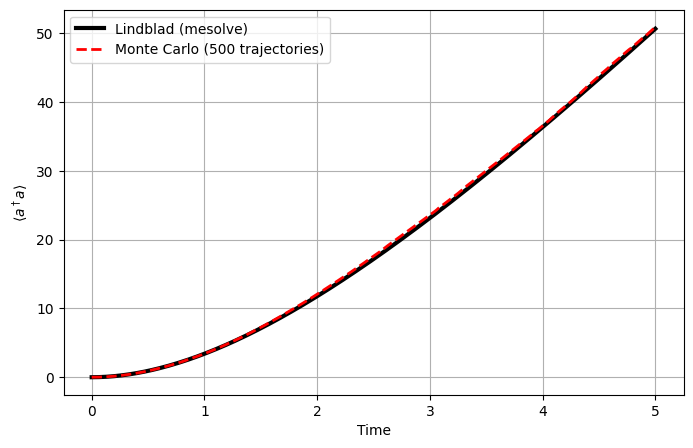

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    times,
    result_me.expect[0],
    lw=3,
    color="black",
    label="Lindblad (mesolve)"
)

plt.plot(
    times,
    mc_average,
    "--",
    lw=2,
    color="red",
    label=f"Monte Carlo ({ntraj} trajectories)"
)

plt.xlabel("Time")

plt.ylabel(r"$\langle a^\dagger a\rangle$")

plt.legend()

plt.grid(True)

plt.show()

As the number of trajectories increases, the statistical fluctuations become progressively smaller and the Monte Carlo estimate converges towards the deterministic solution of the Lindblad master equation. In practice, the statistical error decreases approximately as

$$
\epsilon
\propto
\frac{1}{\sqrt{N_{\rm traj}}},
$$

which is the c**haracteristic convergence law of Monte Carlo methods**.

To illustrate this behavior, the expectation value of the photon number

$$
\langle a^\dagger a\rangle
$$

is computed using different numbers of trajectories and compared with the solution obtained from the Lindblad master equation.

100.0%. Run time:   0.00s. Est. time left: 00:00:00:00
Total run time:   0.01s
10.0%. Run time:   0.01s. Est. time left: 00:00:00:00
20.0%. Run time:   0.02s. Est. time left: 00:00:00:00
30.0%. Run time:   0.04s. Est. time left: 00:00:00:00
40.0%. Run time:   0.06s. Est. time left: 00:00:00:00
50.0%. Run time:   0.07s. Est. time left: 00:00:00:00
60.0%. Run time:   0.09s. Est. time left: 00:00:00:00
70.0%. Run time:   0.11s. Est. time left: 00:00:00:00
80.0%. Run time:   0.12s. Est. time left: 00:00:00:00
90.0%. Run time:   0.14s. Est. time left: 00:00:00:00
100.0%. Run time:   0.16s. Est. time left: 00:00:00:00
Total run time:   0.17s
10.0%. Run time:   0.07s. Est. time left: 00:00:00:00
20.0%. Run time:   0.15s. Est. time left: 00:00:00:00
30.0%. Run time:   0.23s. Est. time left: 00:00:00:00
40.0%. Run time:   0.31s. Est. time left: 00:00:00:00
50.0%. Run time:   0.39s. Est. time left: 00:00:00:00
60.0%. Run time:   0.46s. Est. time left: 00:00:00:00
70.0%. Run time:   0.54s. Est. t

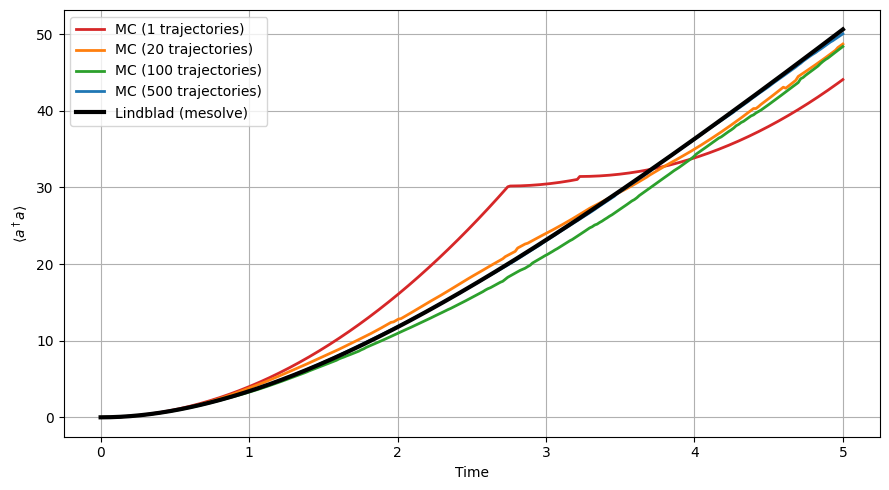

In [ ]:
result_me = qt.mesolve(
    H,
    psi0,
    times,
    c_ops,
    e_ops=[n_op]
)

traj_numbers = [1, 20, 100, 500, 1000]

plt.figure(figsize=(9,5))

colors = ["tab:red","tab:orange","tab:green","tab:blue"]

for ntraj, color in zip(traj_numbers, colors):

    result_mc = qt.mcsolve(
        H,
        psi0,
        times,
        c_ops,
        e_ops=[n_op],
        ntraj=ntraj
    )

    plt.plot(
        times,
        result_mc.expect[0],
        lw=2,
        color=color,
        label=f"MC ({ntraj} trajectories)"
    )

plt.plot(
    times,
    result_me.expect[0],
    color="black",
    lw=3,
    label="Lindblad (mesolve)"
)

plt.xlabel("Time")

plt.ylabel(r"$\langle a^\dagger a\rangle$")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

### WIGNER FUNCTION

The left panel shows the Wigner function corresponding to a **single quantum trajectory**. Since this trajectory represents one particular realization of the stochastic dynamics, the state remains pure and its phase-space distribution exhibits structures that are specific to the sequence of quantum jumps experienced during that realization. Consequently, the Wigner function differs significantly from the ensemble-averaged state.

The central panel corresponds to the density matrix obtained by averaging over **500 independent quantum trajectories**,

$$
\rho_{\rm MC}(t)
=
\frac{1}{N_{\rm traj}}
\sum_{i=1}^{N_{\rm traj}}
|\psi_i(t)\rangle
\langle\psi_i(t)|.
$$

The stochastic fluctuations associated with individual trajectories are progressively suppressed by the averaging procedure.

The right panel shows the Wigner function obtained by solving the Lindblad master equation,

$$
\frac{d\rho}{dt}
=
-i[H,\rho]
+
\sum_k
\left(
L_k\rho L_k^\dagger
-
\frac12
\{L_k^\dagger L_k,\rho\}
\right).
$$

A direct comparison between the central and right panels reveals an excellent agreement. Both Wigner functions display nearly identical phase-space distributions, demonstrating that the ensemble average of the stochastic quantum trajectories converges to the deterministic density matrix predicted by the Lindblad equation.

This comparison constitutes a direct numerical verification of the quantum trajectory formalism. Although each individual trajectory follows a different stochastic evolution, their statistical average reproduces the complete dynamics of the open quantum system.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt


N = 140

alpha = 2.0
gamma = 0.5

T = 5.0
n_steps = 300

times = np.linspace(0, T, n_steps)

a = qt.destroy(N)

I = qt.qeye(N)

parity = sum(
    (-1)**n * qt.basis(N, n) * qt.basis(N, n).dag()
    for n in range(N)
)

P_even = (I + parity)/2
P_odd  = (I - parity)/2


# Hamiltonian

H = 1j*(alpha*a.dag() - np.conjugate(alpha)*a)


# Collapse operators

c_ops = [
    np.sqrt(gamma)*P_even,
    np.sqrt(gamma)*P_odd
]


psi0 = qt.basis(N,0)


# Observable

n_op = a.dag()*a


100.0%. Run time:   0.00s. Est. time left: 00:00:00:00
Total run time:   0.03s
10.0%. Run time:   1.70s. Est. time left: 00:00:00:15
20.0%. Run time:   2.49s. Est. time left: 00:00:00:09
30.0%. Run time:   3.09s. Est. time left: 00:00:00:07
40.0%. Run time:   3.47s. Est. time left: 00:00:00:05
50.0%. Run time:   3.84s. Est. time left: 00:00:00:03
60.0%. Run time:   4.23s. Est. time left: 00:00:00:02
70.0%. Run time:   4.79s. Est. time left: 00:00:00:02
80.0%. Run time:   5.19s. Est. time left: 00:00:00:01
90.0%. Run time:   5.56s. Est. time left: 00:00:00:00
100.0%. Run time:   5.94s. Est. time left: 00:00:00:00
Total run time:   5.95s


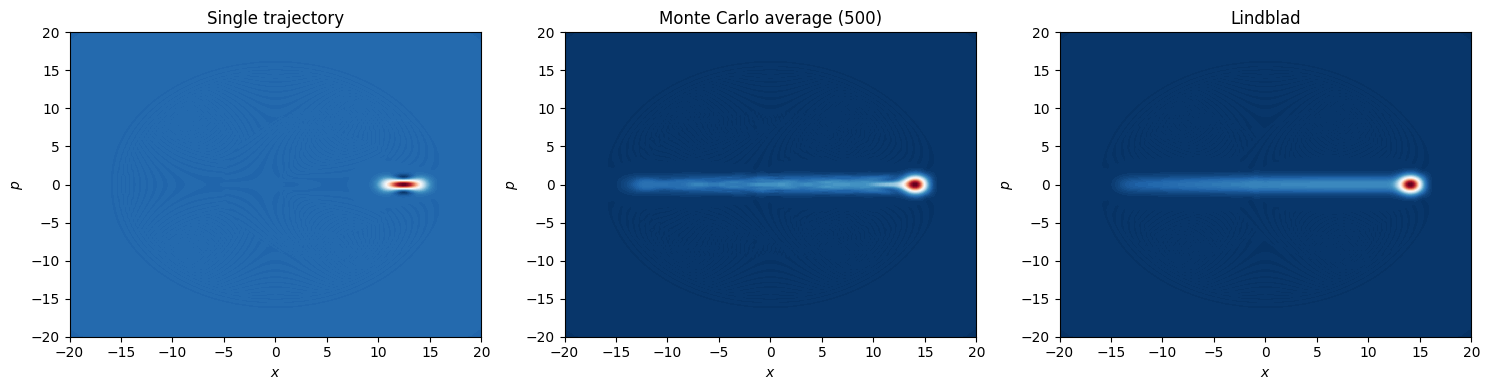

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt


ntraj = 500

x = np.linspace(-20,20,200)


# Monte Carlo: single trajectory


options_single = {
    "store_states": True,
    "keep_runs_results": True,
}

result_single = qt.mcsolve(
    H,
    psi0,
    times,
    c_ops,
    ntraj=1,
    options=options_single
)


# Monte Carlo: many trajectories


options_mc = {
    "store_states": True,
    "keep_runs_results": True,
}

result_mc = qt.mcsolve(
    H,
    psi0,
    times,
    c_ops,
    ntraj=ntraj,
    options=options_mc
)


# Lindblad master equation


result_me = qt.mesolve(
    H,
    psi0,
    times,
    c_ops,
    options={"store_states": True}
)


t_index = -1

psi_single = result_single.runs_states[0][t_index]

rho_mc = 0

for traj in result_mc.runs_states:

    psi = traj[t_index]

    rho_mc += psi.proj()

rho_mc /= len(result_mc.runs_states)


# Lindblad density matrix


rho_me = result_me.states[t_index]


# Wigner functions


W_single = qt.wigner(psi_single, x, x)

W_mc = qt.wigner(rho_mc, x, x)

W_me = qt.wigner(rho_me, x, x)



fig, ax = plt.subplots(1,3,figsize=(15,4))

titles = [
    "Single trajectory",
    f"Monte Carlo average ({ntraj})",
    "Lindblad"
]

Ws = [
    W_single,
    W_mc,
    W_me
]

for a, W, title in zip(ax, Ws, titles):

    im = a.contourf(
        x,
        x,
        W,
        100,
        cmap="RdBu_r"
    )

    a.set_title(title)

    a.set_xlabel(r"$x$")

    a.set_ylabel(r"$p$")



plt.tight_layout()

plt.show()

### Discussion

The Wigner function provides a phase-space representation of the cavity state, allowing both its localization and its quantum coherences to be visualized.

Since the system starts in the vacuum state and is driven by a coherent displacement, **the Hamiltonian continuously generates coherent states**. Consequently, in the absence of measurements, the Wigner function would remain a **Gaussian distribution** whose center is displaced through phase space as energy is injected into the cavity.

The left panel shows the Wigner function of a single quantum trajectory. As the evolution is conditioned on one particular sequence of measurement outcomes, the final state remains pure and the Wigner function is sharply localized around a single coherent amplitude.

The Monte Carlo average and the Lindblad solution are almost indistinguishable, confirming that averaging a sufficiently large number of stochastic trajectories reproduces the deterministic master-equation dynamics. Compared with a single trajectory, both exhibit a broader distribution with an elongated tail. This broadening is a signature of **measurement-induced decoherence**: different trajectories end in slightly different coherent states, and their statistical mixture produces a more extended Wigner function. The coherent displacement generated by the Hamiltonian is preserved, while the continuous parity measurements progressively reduce the quantum coherence of the ensemble.

In a closed system, a single wave function completely describes the physical evolution. In**an open system**, however, each quantum trajectory corresponds to one possible realization of the **stochastic measurement process**. Individual trajectories are therefore different, even when they start from the same initial state. The physical state of **the open quantum system is recovered only after averaging over many independent trajectories**, reproducing the density matrix obtained from the Lindblad master equation.

The numerical simulations performed in this notebook confirm this correspondence. While individual trajectories exhibit stochastic quantum jumps, their ensemble average converges to the deterministic Lindblad solution, both in the expectation value of the photon number and in the phase-space representation given by the Wigner function. These results illustrate how the quantum trajectory formalism provides an intuitive picture of open-system dynamics by connecting individual stochastic realizations with the ensemble description of the density matrix.

### Different Initial State

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt


N = 200

alpha = 2.0
gamma = 0.5


alpha0 = 2.0

psi0 = qt.coherent(N, alpha0)

T = 5.0
n_steps = 300

times = np.linspace(0, T, n_steps)

a = qt.destroy(N)

I = qt.qeye(N)

parity = sum(
    (-1)**n * qt.basis(N, n) * qt.basis(N, n).dag()
    for n in range(N)
)

P_even = (I + parity)/2
P_odd  = (I - parity)/2


# Hamiltonian

H = 1j*(alpha*a.dag() - np.conjugate(alpha)*a)


# Collapse operators

c_ops = [
    np.sqrt(gamma)*P_even,
    np.sqrt(gamma)*P_odd
]


# Observable

n_op = a.dag()*a


100.0%. Run time:   0.00s. Est. time left: 00:00:00:00
Total run time:   0.07s
10.0%. Run time:   2.31s. Est. time left: 00:00:00:20
20.0%. Run time:   3.31s. Est. time left: 00:00:00:13
30.0%. Run time:   3.81s. Est. time left: 00:00:00:08
40.0%. Run time:   4.55s. Est. time left: 00:00:00:06
50.0%. Run time:   5.01s. Est. time left: 00:00:00:05
60.0%. Run time:   5.46s. Est. time left: 00:00:00:03
70.0%. Run time:   5.92s. Est. time left: 00:00:00:02
80.0%. Run time:   6.37s. Est. time left: 00:00:00:01
90.0%. Run time:   6.99s. Est. time left: 00:00:00:00
100.0%. Run time:   7.44s. Est. time left: 00:00:00:00
Total run time:   7.45s


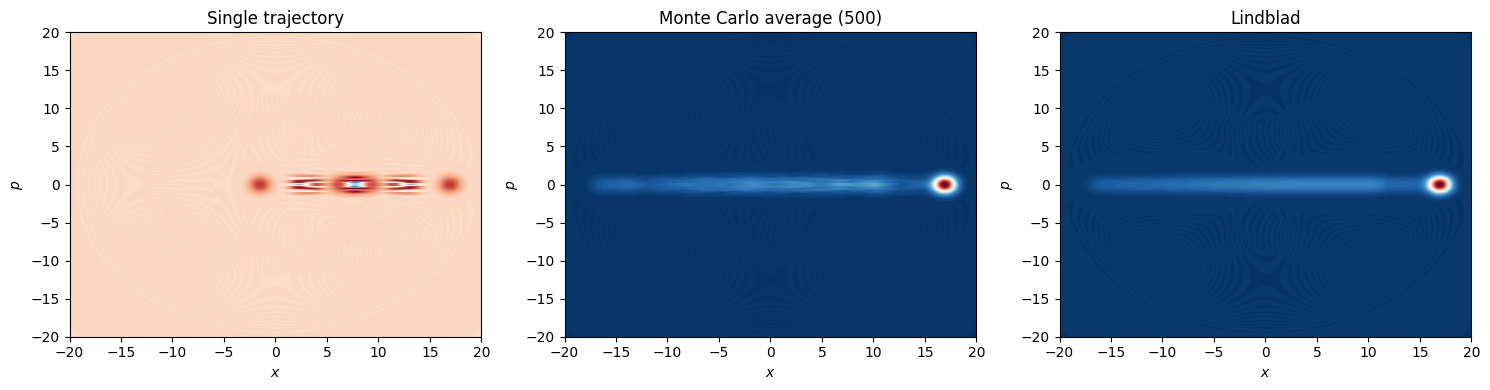

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt


ntraj = 500

x = np.linspace(-20,20,200)


# Monte Carlo: single trajectory


options_single = {
    "store_states": True,
    "keep_runs_results": True,
}

result_single = qt.mcsolve(
    H,
    psi0,
    times,
    c_ops,
    ntraj=1,
    options=options_single
)


# Monte Carlo: many trajectories


options_mc = {
    "store_states": True,
    "keep_runs_results": True,
}

result_mc = qt.mcsolve(
    H,
    psi0,
    times,
    c_ops,
    ntraj=ntraj,
    options=options_mc
)


# Lindblad master equation


result_me = qt.mesolve(
    H,
    psi0,
    times,
    c_ops,
    options={"store_states": True}
)


t_index = -1

psi_single = result_single.runs_states[0][t_index]

rho_mc = 0

for traj in result_mc.runs_states:

    psi = traj[t_index]

    rho_mc += psi.proj()

rho_mc /= len(result_mc.runs_states)


# Lindblad density matrix


rho_me = result_me.states[t_index]


# Wigner functions


W_single = qt.wigner(psi_single, x, x)

W_mc = qt.wigner(rho_mc, x, x)

W_me = qt.wigner(rho_me, x, x)



fig, ax = plt.subplots(1,3,figsize=(15,4))

titles = [
    "Single trajectory",
    f"Monte Carlo average ({ntraj})",
    "Lindblad"
]

Ws = [
    W_single,
    W_mc,
    W_me
]

for a, W, title in zip(ax, Ws, titles):

    im = a.contourf(
        x,
        x,
        W,
        100,
        cmap="RdBu_r"
    )

    a.set_title(title)

    a.set_xlabel(r"$x$")

    a.set_ylabel(r"$p$")



plt.tight_layout()

plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt


N = 200

alpha = 2.0
gamma = 0.5

alpha0 = 2.0

psi_even = (
    qt.coherent(N, alpha0)
    + qt.coherent(N, -alpha0)
).unit()

psi_odd = (
    qt.coherent(N, alpha0)
    - qt.coherent(N, -alpha0)
).unit()

psi0 = psi_even

T = 5.0
n_steps = 300

times = np.linspace(0, T, n_steps)

a = qt.destroy(N)

I = qt.qeye(N)

parity = sum(
    (-1)**n * qt.basis(N, n) * qt.basis(N, n).dag()
    for n in range(N)
)

P_even = (I + parity)/2
P_odd  = (I - parity)/2


# Hamiltonian

H = 1j*(alpha*a.dag() - np.conjugate(alpha)*a)


# Collapse operators

c_ops = [
    np.sqrt(gamma)*P_even,
    np.sqrt(gamma)*P_odd
]



# Observable

n_op = a.dag()*a


100.0%. Run time:   0.00s. Est. time left: 00:00:00:00
Total run time:   0.01s
10.0%. Run time:   0.52s. Est. time left: 00:00:00:04
20.0%. Run time:   1.04s. Est. time left: 00:00:00:04
30.0%. Run time:   1.57s. Est. time left: 00:00:00:03
40.0%. Run time:   2.13s. Est. time left: 00:00:00:03
50.0%. Run time:   2.65s. Est. time left: 00:00:00:02
60.0%. Run time:   3.38s. Est. time left: 00:00:00:02
70.0%. Run time:   3.83s. Est. time left: 00:00:00:01
80.0%. Run time:   4.30s. Est. time left: 00:00:00:01
90.0%. Run time:   4.76s. Est. time left: 00:00:00:00
100.0%. Run time:   5.22s. Est. time left: 00:00:00:00
Total run time:   5.23s


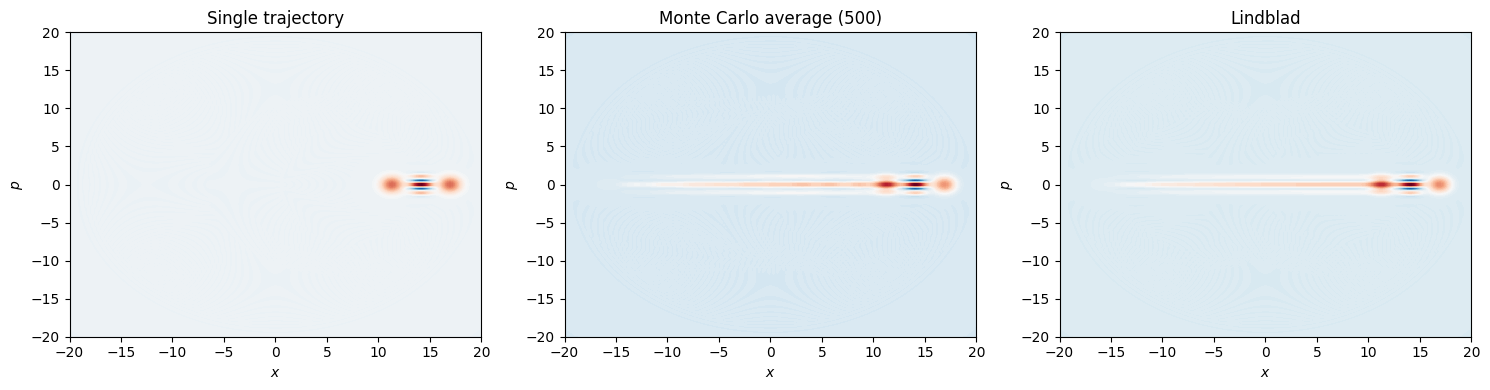

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt


ntraj = 500

x = np.linspace(-20,20,200)


# Monte Carlo: single trajectory


options_single = {
    "store_states": True,
    "keep_runs_results": True,
}

result_single = qt.mcsolve(
    H,
    psi0,
    times,
    c_ops,
    ntraj=1,
    options=options_single
)


# Monte Carlo: many trajectories


options_mc = {
    "store_states": True,
    "keep_runs_results": True,
}

result_mc = qt.mcsolve(
    H,
    psi0,
    times,
    c_ops,
    ntraj=ntraj,
    options=options_mc
)


# Lindblad master equation


result_me = qt.mesolve(
    H,
    psi0,
    times,
    c_ops,
    options={"store_states": True}
)


t_index = -1

psi_single = result_single.runs_states[0][t_index]

rho_mc = 0

for traj in result_mc.runs_states:

    psi = traj[t_index]

    rho_mc += psi.proj()

rho_mc /= len(result_mc.runs_states)


# Lindblad density matrix


rho_me = result_me.states[t_index]


# Wigner functions


W_single = qt.wigner(psi_single, x, x)

W_mc = qt.wigner(rho_mc, x, x)

W_me = qt.wigner(rho_me, x, x)



fig, ax = plt.subplots(1,3,figsize=(15,4))

titles = [
    "Single trajectory",
    f"Monte Carlo average ({ntraj})",
    "Lindblad"
]

Ws = [
    W_single,
    W_mc,
    W_me
]

for a, W, title in zip(ax, Ws, titles):

    im = a.contourf(
        x,
        x,
        W,
        100,
        cmap="RdBu_r"
    )

    a.set_title(title)

    a.set_xlabel(r"$x$")

    a.set_ylabel(r"$p$")



plt.tight_layout()

plt.show()

Changing the initial state does not qualitatively modify the unconditional dynamics. In both cases, the coherent drive continuously displaces the state through phase space, while the continuous parity measurement induces decoherence without projecting the unconditional state onto a definite parity sector. Unlike the ideal projective measurement of a closed system, the continuous measurement only suppresses quantum coherences after averaging over trajectories, whereas the coherent displacement generated by the Hamiltonian remains essentially unchanged.